# Surprise Test 1

In [155]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,accuracy_score,precision_score,recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import joblib

In [156]:
import warnings
warnings.filterwarnings('ignore')

In [157]:
df = pd.read_csv('data/students.csv')
df

,Student_ID,Age,Gender,Department,Semester,Attendance_Percentage,Study_Hours_Per_Day,Internal_Marks,Assignment_Score,Backlogs,Extracurricular_Activities,Sleep_Hours,Internet_Usage_Hours,Previous_Semester_GPA,Result
0,1,27,Male,Computer-Science,4,98.17,2.3,4,94,2,Dance,10.1,8.9,9.53,Fail
1,2,30,Male,Computer-Science,2,13.86,15.2,40,4,4,Music,5.4,6.2,5.00,Fail
2,3,26,Female,Biotechnology,5,41.20,8.7,17,7,7,Music,5.6,2.9,1.59,Fail
3,4,24,Male,Mechanical-Engineering,3,14.17,11.4,3,66,7,Drama,13.4,7.5,2.83,Fail
4,5,24,Male,Civil-Engineering,3,79.70,12.9,26,11,4,Volunteer Work,1.3,13.8,4.62,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,28,Female,Civil-Engineering,7,93.43,13.2,36,2,10,Music,1.5,6.7,1.04,Pass
996,997,28,Female,Business-Administration,8,74.08,15.0,17,69,1,Volunteer Work,12.5,15.0,7.33,Fail
997,998,17,Male,Civil-Engineering,5,56.08,11.3,6,43,1,Dance,2.8,13.6,0.74,Fail
998,999,26,Male,Electrical-Engineering,1,72.98,14.5,18,99,7,Robotics Club,13.0,11.9,3.44,Pass


<Axes: xlabel='Previous_Semester_GPA', ylabel='Density'>

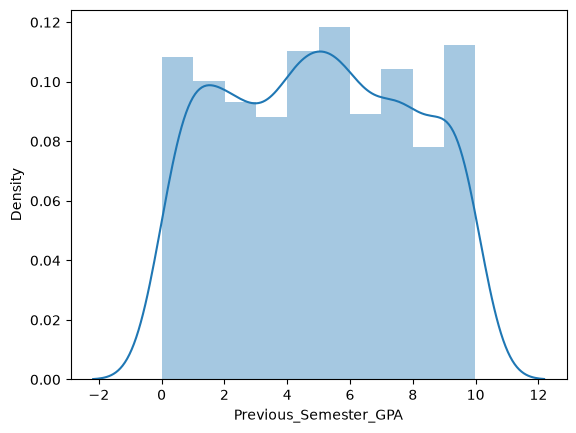

In [158]:
sns.distplot(df.Previous_Semester_GPA)

In [159]:
df.isna().sum().T

Student_ID                    0
Age                           0
Gender                        0
Department                    0
Semester                      0
Attendance_Percentage         0
Study_Hours_Per_Day           0
Internal_Marks                0
Assignment_Score              0
Backlogs                      0
Extracurricular_Activities    0
Sleep_Hours                   0
Internet_Usage_Hours          0
Previous_Semester_GPA         0
Result                        0
dtype: int64

In [160]:
df = df.drop(['Student_ID','Extracurricular_Activities'],axis=1)
df

,Age,Gender,Department,Semester,Attendance_Percentage,Study_Hours_Per_Day,Internal_Marks,Assignment_Score,Backlogs,Sleep_Hours,Internet_Usage_Hours,Previous_Semester_GPA,Result
0,27,Male,Computer-Science,4,98.17,2.3,4,94,2,10.1,8.9,9.53,Fail
1,30,Male,Computer-Science,2,13.86,15.2,40,4,4,5.4,6.2,5.00,Fail
2,26,Female,Biotechnology,5,41.20,8.7,17,7,7,5.6,2.9,1.59,Fail
3,24,Male,Mechanical-Engineering,3,14.17,11.4,3,66,7,13.4,7.5,2.83,Fail
4,24,Male,Civil-Engineering,3,79.70,12.9,26,11,4,1.3,13.8,4.62,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,28,Female,Civil-Engineering,7,93.43,13.2,36,2,10,1.5,6.7,1.04,Pass
996,28,Female,Business-Administration,8,74.08,15.0,17,69,1,12.5,15.0,7.33,Fail
997,17,Male,Civil-Engineering,5,56.08,11.3,6,43,1,2.8,13.6,0.74,Fail
998,26,Male,Electrical-Engineering,1,72.98,14.5,18,99,7,13.0,11.9,3.44,Pass


In [161]:
df['Gender'] = df['Gender'].map({'Male':1, 'Female':0})
df

,Age,Gender,Department,Semester,Attendance_Percentage,Study_Hours_Per_Day,Internal_Marks,Assignment_Score,Backlogs,Sleep_Hours,Internet_Usage_Hours,Previous_Semester_GPA,Result
0,27,1,Computer-Science,4,98.17,2.3,4,94,2,10.1,8.9,9.53,Fail
1,30,1,Computer-Science,2,13.86,15.2,40,4,4,5.4,6.2,5.00,Fail
2,26,0,Biotechnology,5,41.20,8.7,17,7,7,5.6,2.9,1.59,Fail
3,24,1,Mechanical-Engineering,3,14.17,11.4,3,66,7,13.4,7.5,2.83,Fail
4,24,1,Civil-Engineering,3,79.70,12.9,26,11,4,1.3,13.8,4.62,Fail
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,28,0,Civil-Engineering,7,93.43,13.2,36,2,10,1.5,6.7,1.04,Pass
996,28,0,Business-Administration,8,74.08,15.0,17,69,1,12.5,15.0,7.33,Fail
997,17,1,Civil-Engineering,5,56.08,11.3,6,43,1,2.8,13.6,0.74,Fail
998,26,1,Electrical-Engineering,1,72.98,14.5,18,99,7,13.0,11.9,3.44,Pass


In [162]:
x = df.loc[:,:'Previous_Semester_GPA']
x

,Age,Gender,Department,Semester,Attendance_Percentage,Study_Hours_Per_Day,Internal_Marks,Assignment_Score,Backlogs,Sleep_Hours,Internet_Usage_Hours,Previous_Semester_GPA
0,27,1,Computer-Science,4,98.17,2.3,4,94,2,10.1,8.9,9.53
1,30,1,Computer-Science,2,13.86,15.2,40,4,4,5.4,6.2,5.00
2,26,0,Biotechnology,5,41.20,8.7,17,7,7,5.6,2.9,1.59
3,24,1,Mechanical-Engineering,3,14.17,11.4,3,66,7,13.4,7.5,2.83
4,24,1,Civil-Engineering,3,79.70,12.9,26,11,4,1.3,13.8,4.62
...,...,...,...,...,...,...,...,...,...,...,...,...
995,28,0,Civil-Engineering,7,93.43,13.2,36,2,10,1.5,6.7,1.04
996,28,0,Business-Administration,8,74.08,15.0,17,69,1,12.5,15.0,7.33
997,17,1,Civil-Engineering,5,56.08,11.3,6,43,1,2.8,13.6,0.74
998,26,1,Electrical-Engineering,1,72.98,14.5,18,99,7,13.0,11.9,3.44


In [163]:
x = pd.get_dummies(x,columns=['Department'],drop_first=True)
x

,Age,Gender,Semester,Attendance_Percentage,Study_Hours_Per_Day,Internal_Marks,Assignment_Score,Backlogs,Sleep_Hours,Internet_Usage_Hours,Previous_Semester_GPA,Department_Business-Administration,Department_Civil-Engineering,Department_Computer-Science,Department_Electrical-Engineering,Department_Mechanical-Engineering
0,27,1,4,98.17,2.3,4,94,2,10.1,8.9,9.53,False,False,True,False,False
1,30,1,2,13.86,15.2,40,4,4,5.4,6.2,5.00,False,False,True,False,False
2,26,0,5,41.20,8.7,17,7,7,5.6,2.9,1.59,False,False,False,False,False
3,24,1,3,14.17,11.4,3,66,7,13.4,7.5,2.83,False,False,False,False,True
4,24,1,3,79.70,12.9,26,11,4,1.3,13.8,4.62,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,28,0,7,93.43,13.2,36,2,10,1.5,6.7,1.04,False,True,False,False,False
996,28,0,8,74.08,15.0,17,69,1,12.5,15.0,7.33,True,False,False,False,False
997,17,1,5,56.08,11.3,6,43,1,2.8,13.6,0.74,False,True,False,False,False
998,26,1,1,72.98,14.5,18,99,7,13.0,11.9,3.44,False,False,False,True,False


In [164]:
y:pd.DataFrame = df['Result']
y

0      Fail
1      Fail
2      Fail
3      Fail
4      Fail
       ... 
995    Pass
996    Fail
997    Fail
998    Pass
999    Pass
Name: Result, Length: 1000, dtype: str

In [165]:
y.value_counts()

Result
Pass    508
Fail    492
Name: count, dtype: int64

In [166]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.8,random_state=987)

In [167]:
lr = LogisticRegression(solver='newton-cholesky')

In [168]:
model_lr = lr.fit(xtrain,ytrain)

In [169]:
pred = model_lr.predict(xtest)

In [170]:
report_lr = classification_report(pred,ytest)
print(report_lr)

              precision    recall  f1-score   support

        Fail       0.44      0.46      0.45        93
        Pass       0.51      0.50      0.50       107

    accuracy                           0.48       200
   macro avg       0.48      0.48      0.48       200
weighted avg       0.48      0.48      0.48       200



In [171]:
dtree = DecisionTreeClassifier(max_depth=5)

In [172]:
model_dt = dtree.fit(xtrain,ytrain)

In [173]:
pred_dt = model_dt.predict(xtest)

In [174]:
report_dt = classification_report(pred_dt,ytest)
print(report_dt)

              precision    recall  f1-score   support

        Fail       0.48      0.47      0.48       100
        Pass       0.49      0.50      0.49       100

    accuracy                           0.48       200
   macro avg       0.48      0.48      0.48       200
weighted avg       0.48      0.48      0.48       200



In [175]:
rf = RandomForestClassifier(n_estimators=100,max_depth=5)

In [176]:
model_rf = rf.fit(xtrain,ytrain)

In [177]:
pred3 = model_rf.predict(xtest)

In [178]:
report_rf = classification_report(pred3,ytest)
print(report_rf)

              precision    recall  f1-score   support

        Fail       0.47      0.55      0.51        84
        Pass       0.63      0.56      0.59       116

    accuracy                           0.56       200
   macro avg       0.55      0.55      0.55       200
weighted avg       0.57      0.56      0.56       200



In [179]:
joblib.dump(model_dt,'DT-Model.joblib')

['DT-Model.joblib']